<a href="https://colab.research.google.com/github/pavlek358/dsb_capstone/blob/main/croatia_procurement_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone – Croatian Public Procurement: EDA
**Goal:** understand the data before predicting **number of bids per tender**.

**Data:** OpenTender / Government Transparency Institute, Croatia file `HR_DIB_2023.csv` (download from opentender.eu/hr → Download, put it in `data/`).

## 1. Imports

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)

## 2. Load data

In [74]:
df = pd.read_csv('/content/HR_DIB_2023.csv', low_memory=False)
df.shape

(473967, 126)

In [75]:
df.head()

,persistent_id,tender_id,tender_title,tender_proceduretype,tender_nationalproceduretype,tender_isawarded,tender_supplytype,tender_biddeadline,tender_isjointprocurement,tender_lotscount,tender_recordedbidscount,tender_isframeworkagreement,tender_isdps,tender_contractsignaturedate,tender_cpvs,tender_maincpv,tender_iseufunded,tender_selectionmethod,tender_awardcriteria_count,tender_cancellationdate,cancellation_reason,tender_awarddecisiondate,tender_estimatedprice,tender_finalprice,lot_estimatedprice,...,bid_digiwhist_price,lot_id,bid_id,bid_priceUsd,lot_estimatedpriceUsd,tender_estimatedpriceUsd,tender_finalpriceUsd,filter_framework,filter_buyer,filter_bidder,filter_cancelled,filter_opentender,filter_year,filter_losingbids,filter_ok,corr_singleb,corr_proc,submission_period,corr_subm,corr_nocft,decision_period,corr_decp,corr_tax_haven,corr_buyer_concentration,cri
0,EU_dde719421f42ccd4ae7d536f2027da0a8140ea2df3e...,6a0cd51b-90cc-4d67-9a21-2216bafcbdbf,NaN,RESTRICTED,NaN,NaN,WORKS,2008-02-21,NaN,1,0,f,f,NaN,"45253700,",t,f,MEAT,8,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,group_EU_tender_dd2ad9688c9399c357f0431f0194e1...,NaN,NaN,NaN,NaN,NaN,True,True,False,True,True,False,True,False,NaN,0.0,NaN,NaN,1,NaN,NaN,NaN,NaN,0.5
1,EU_dde719421f42ccd4ae7d536f2027da0a8140ea2df3e...,d3b6e8f5-7e6d-4204-89f5-680423570cc0,NaN,RESTRICTED,NaN,NaN,WORKS,2008-02-21,NaN,1,0,f,f,NaN,"45253700,",t,f,MEAT,8,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,group_EU_tender_c3f6bb94699c6d3c57e30ca1c41c73...,NaN,NaN,NaN,NaN,NaN,True,True,False,True,True,False,True,False,NaN,0.0,NaN,NaN,1,NaN,NaN,NaN,NaN,0.5
2,HR_00089058a58d79bdd2614936b22dc85dc2dc44a1687...,e609d030-c590-4414-87db-30f33426a8e8,Nabava komunalnog traktora s priključcima: mal...,OPEN,Otvoreni postupak,NaN,NaN,NaN,NaN,1,0,f,NaN,NaN,"29370000,",t,NaN,LOWEST_PRICE,1,NaN,NaN,NaN,499900.0,NaN,NaN,...,NaN,group_HR_tender_1d245fc21728878b2c3e4af08664ef...,NaN,NaN,NaN,129092.138154,NaN,True,True,False,True,True,False,True,False,NaN,0.0,NaN,NaN,1,NaN,NaN,NaN,NaN,0.5
3,HR_0009142c1b2055c60cbb43b1e347bbcb9a896f7646b...,004da69d-893a-4b2f-89c0-168aac67f93c,NaN,NaN,NaN,NaN,SERVICES,NaN,NaN,1,0,NaN,NaN,NaN,"90313000,",t,NaN,NaN,0,NaN,NaN,NaN,200000.0,NaN,NaN,...,NaN,group_HR_tender_33b9be201b0aeef9ad0d155596625e...,NaN,NaN,NaN,51647.184699,NaN,True,True,False,True,True,False,True,False,NaN,1.0,NaN,NaN,1,NaN,NaN,NaN,NaN,1.0
4,HR_00097b89b2d02163c69b97c99f35c9e33838d9abaf1...,9680d510-39d3-40da-b55a-d6d75c1e4977,Pilot projekt navodnjavanja Novaljsko poljePil...,OPEN,Otvoreni postupak,NaN,NaN,NaN,NaN,1,0,f,NaN,NaN,"74232200,",t,NaN,MEAT,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,group_HR_tender_be4928f1ba7fff18fad303424c98e1...,NaN,NaN,NaN,NaN,NaN,True,True,False,True,True,False,True,False,NaN,0.0,NaN,NaN,1,NaN,NaN,NaN,NaN,0.5


One row = one **bid**, not one tender.

In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 257461 entries, 401 to 473966
Data columns (total 20 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   tender_id                 257461 non-null  object 
 1   tender_year               257461 non-null  float64
 2   tender_title              257458 non-null  object 
 3   tender_proceduretype      244973 non-null  object 
 4   tender_supplytype         256658 non-null  object 
 5   tender_maincpv            257461 non-null  object 
 6   tender_lotscount          257461 non-null  int64  
 7   tender_recordedbidscount  257461 non-null  int64  
 8   tender_estimatedprice     183081 non-null  float64
 9   tender_finalprice         235523 non-null  float64
 10  lot_status                257409 non-null  object 
 11  buyer_id                  253120 non-null  object 
 12  buyer_name                257461 non-null  object 
 13  buyer_city                257461 non-null  obje

In [102]:
# 1. Totals: rows, unique tenders, unique bidders
print('rows:', len(df))
print('unique tender_id:', df['tender_id'].nunique())
print('unique bidder_id:', df['bidder_id'].nunique())

rows: 257461
unique tender_id: 167343
unique bidder_id: 10650


In [103]:
# 2. Empty bidder_id: how many rows and what share
print('empty bidder_id rows:', df['bidder_id'].isna().sum())
print('share empty:', df['bidder_id'].isna().mean().round(3))

empty bidder_id rows: 39172
share empty: 0.152


In [104]:
# 3. Same for tender_id (should be 0 empty)
print('empty tender_id rows:', df['tender_id'].isna().sum())

empty tender_id rows: 0


In [101]:
# rows per tender vs recorded bids
check = df.groupby('tender_id').agg(rows=('bidder_id', 'count'),
                                    bidders=('bidder_id', 'nunique'),
                                    bids=('tender_recordedbidscount', 'max'))
check.head(10)

,rows,bidders,bids
tender_id,,,
00006bc3-98d0-44a2-b030-043f48cedd6a,1,1,1
00012d98-2aff-43ac-962a-eca9e2d8aaab,1,1,1
00013434-f3c2-4fbd-b3dc-8d5c40098c89,0,0,1
00015894-0e44-45c9-8733-d7e75b88d637,0,0,1
00018b54-2a04-4bf4-99d6-a4d839fadf20,2,1,1
0001b155-7bd5-4d89-a8e7-9d78a9f29696,1,1,1
0001d801-c898-4522-957d-57578ff62c0f,0,0,1
0001df74-52c7-4b42-9d4c-37eed18e615c,1,1,1
00024d9f-7cc7-421a-ba83-424d976c5073,2,2,1


In [99]:
df.tender_id.value_counts() #.plot()

,count
tender_id,
f326d04d-5e1c-494f-ab0d-bfc3083754a6,545
520440ce-85b6-4952-8c46-38eeba7e701d,400
26fba94e-a792-4d5a-914b-b6f9561acaa0,383
5942593e-9311-4103-be55-fe775cdeb2cc,305
a526693f-eec1-45c1-af62-0cce215616e0,276
...,...
38596b22-e36e-40f3-9f9d-f10390578cf6,1
79b894e3-e04c-4f5a-ba94-d38a55d19cb9,1
ba3a4c4d-c02a-4c13-89b2-179a1c4a887c,1


## 3. Keep useful columns

In [76]:
cols = ['tender_id', 'tender_year', 'tender_title', 'tender_proceduretype', 'tender_supplytype',
        'tender_maincpv', 'tender_lotscount', 'tender_isEUfunded',
        'tender_recordedbidscount', 'tender_estimatedprice', 'tender_finalprice',
        'lot_status', 'buyer_id', 'buyer_name', 'buyer_city', 'buyer_buyertype',
        'bidder_id', 'bidder_name', 'bid_price', 'currency', 'filter_ok']

cols = [c for c in cols if c in df.columns]   # keep only the ones that exist
df = df[cols]
df.columns

Index(['tender_id', 'tender_year', 'tender_title', 'tender_proceduretype',
       'tender_supplytype', 'tender_maincpv', 'tender_lotscount',
       'tender_recordedbidscount', 'tender_estimatedprice',
       'tender_finalprice', 'lot_status', 'buyer_id', 'buyer_name',
       'buyer_city', 'buyer_buyertype', 'bidder_id', 'bidder_name',
       'bid_price', 'currency', 'filter_ok'],
      dtype='object')

## 4. Missing values

In [77]:
df.isna().mean().sort_values(ascending=False).round(2)

,0
bid_price,0.40
bidder_id,0.37
tender_estimatedprice,0.33
bidder_name,0.27
tender_finalprice,0.23
tender_proceduretype,0.06
tender_supplytype,0.05
buyer_buyertype,0.03
buyer_id,0.03
tender_title,0.02


Prices are often missing, bids count is the column that matters most.

## 5. Clean

In [78]:
if 'filter_ok' in df.columns:
    df = df[df['filter_ok'] == 1]          # GTI flag for usable rows

df = df.dropna(subset=['tender_recordedbidscount'])
df.shape

(257461, 20)

### One row per tender

In [79]:
tenders = df.drop_duplicates(subset='tender_id').copy()
print('bid rows:', len(df), '| tenders:', len(tenders))

bid rows: 257461 | tenders: 167343


## 6. Target: number of bids

In [100]:
tenders['tender_recordedbidscount'].describe().round(3)

,tender_recordedbidscount
count,167343.000
mean,1.046
std,0.490
min,1.000
25%,1.000
50%,1.000
75%,1.000
max,24.000


In [81]:
tenders['tender_recordedbidscount'].value_counts(normalize=True).head(10).round(3)

,proportion
tender_recordedbidscount,
1,0.983
2,0.007
3,0.004
4,0.002
5,0.001
6,0.001
7,0.000
8,0.000
9,0.000


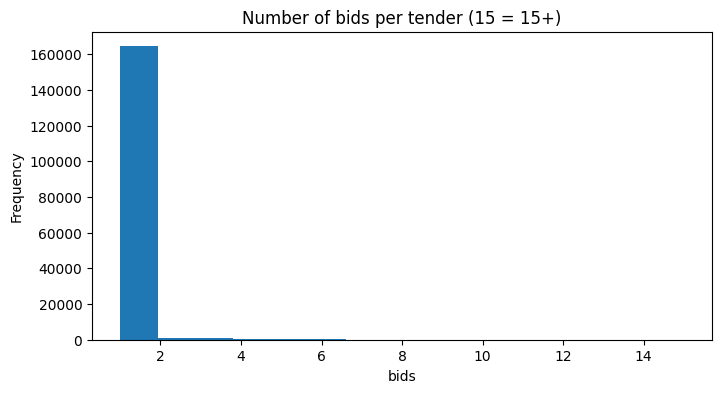

In [82]:
tenders['tender_recordedbidscount'].clip(upper=15).plot(kind='hist', bins=15, figsize=(8,4))
plt.title('Number of bids per tender (15 = 15+)')
plt.xlabel('bids'); plt.show()

In [83]:
tenders['single_bid'] = (tenders['tender_recordedbidscount'] == 1).astype(int)
print('Single-bid share:', round(tenders['single_bid'].mean(), 3))

Single-bid share: 0.983


Skewed to the right, most tenders get only a few bids.

## 7. Over time

In [84]:
by_year = tenders.groupby('tender_year').agg(tenders=('tender_id', 'count'),
                                             avg_bids=('tender_recordedbidscount', 'mean'),
                                             single_bid=('single_bid', 'mean'))
by_year.round(2)

,tenders,avg_bids,single_bid
tender_year,,,
2007.0,1,1.00,1.00
2008.0,13030,1.00,1.00
2009.0,13721,1.00,1.00
2010.0,13183,1.00,1.00
2011.0,14531,1.00,1.00
2012.0,13062,1.01,0.99
2013.0,14097,1.03,0.98
2014.0,9374,1.06,0.98
2015.0,8370,1.09,0.97


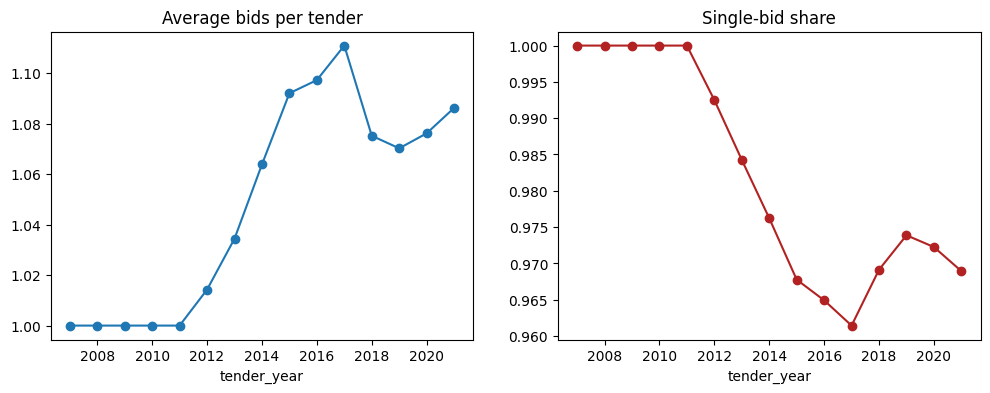

In [85]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
by_year['avg_bids'].plot(ax=ax[0], marker='o', title='Average bids per tender')
by_year['single_bid'].plot(ax=ax[1], marker='o', color='firebrick', title='Single-bid share')
plt.show()

## 8. Bids by category

In [86]:
for col in ['tender_proceduretype', 'tender_supplytype', 'buyer_buyertype']:
    if col in tenders.columns:
        print(tenders.groupby(col)['tender_recordedbidscount'].agg(['count', 'mean']).round(2)
              .sort_values('count', ascending=False), '\n')

                                 count  mean
tender_proceduretype                        
OPEN                            143058  1.05
NEGOTIATED_WITHOUT_PUBLICATION    7063  1.00
OUTRIGHT_AWARD                    2561  1.00
NEGOTIATED_WITH_PUBLICATION       1338  1.04
RESTRICTED                        1084  1.09
NEGOTIATED                          61  1.31
COMPETITIVE_DIALOG                   5  1.00 

                   count  mean
tender_supplytype             
SUPPLIES           73923  1.07
SERVICES           51909  1.03
WORKS              41270  1.02 

                    count  mean
buyer_buyertype                
PUBLIC_BODY         79582  1.06
REGIONAL_AUTHORITY  37454  1.03
OTHER               29600  1.03
NATIONAL_AUTHORITY  16339  1.03
UTILITIES            1969  1.26
NATIONAL_AGENCY      1131  1.10
REGIONAL_AGENCY       360  1.01
EUROPEAN_AGENCY         6  2.00 



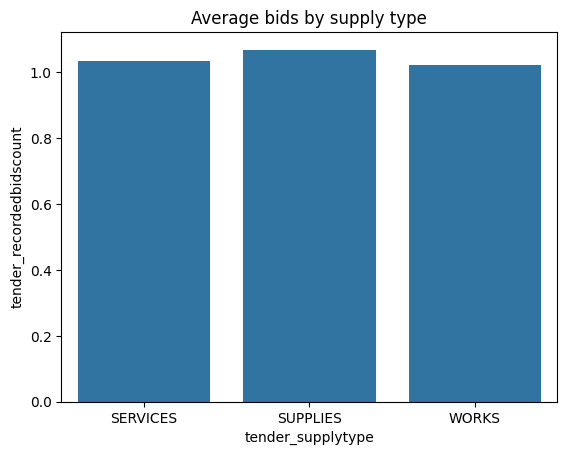

In [87]:
sns.barplot(data=tenders, x='tender_supplytype', y='tender_recordedbidscount', errorbar=None)
plt.title('Average bids by supply type'); plt.show()

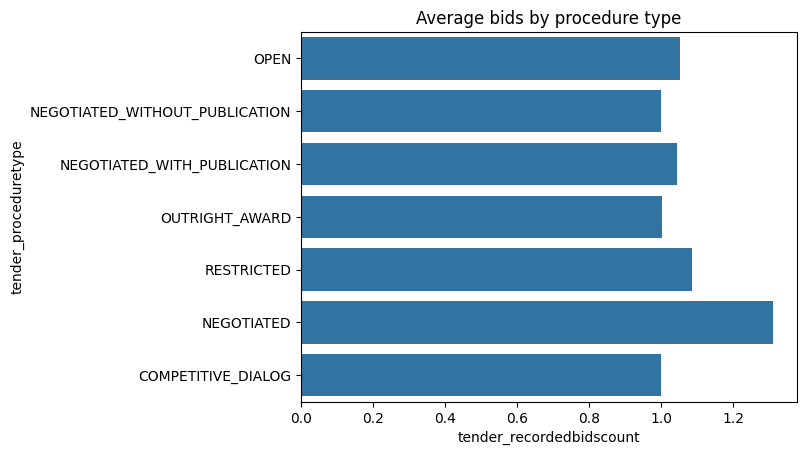

In [88]:
sns.barplot(data=tenders, y='tender_proceduretype', x='tender_recordedbidscount', errorbar=None)
plt.title('Average bids by procedure type'); plt.show()

### CPV sector (first 2 digits)

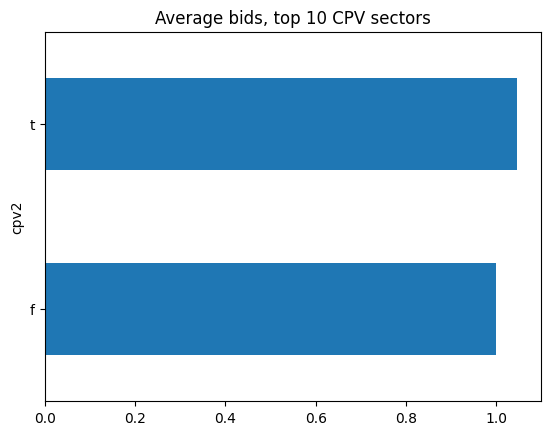

In [89]:
if 'tender_maincpv' in tenders.columns:
    tenders['cpv2'] = tenders['tender_maincpv'].astype(str).str[:2]
    top_cpv = tenders['cpv2'].value_counts().head(10).index
    (tenders[tenders['cpv2'].isin(top_cpv)]
        .groupby('cpv2')['tender_recordedbidscount'].mean()
        .sort_values().plot(kind='barh', title='Average bids, top 10 CPV sectors'))
    plt.show()

## 9. Price vs bids

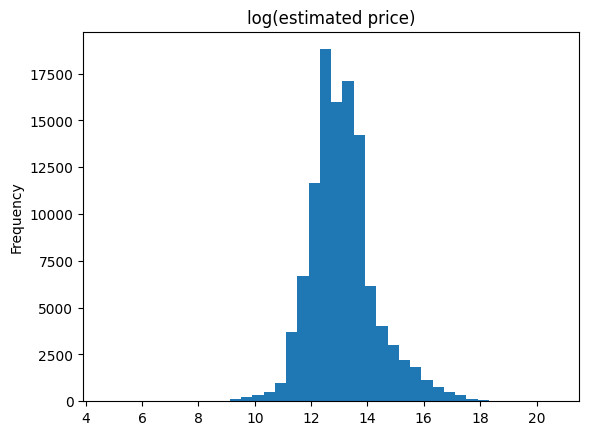

In [90]:
tenders['log_est_price'] = np.log1p(tenders['tender_estimatedprice'])
tenders['log_est_price'].plot(kind='hist', bins=40, title='log(estimated price)'); plt.show()

In [91]:
tenders['price_group'] = pd.qcut(tenders['tender_estimatedprice'], 5,
                                 labels=['very low', 'low', 'mid', 'high', 'very high'])
tenders.groupby('price_group', observed=True)['tender_recordedbidscount'].mean().round(2)

,tender_recordedbidscount
price_group,
very low,1.01
low,1.04
mid,1.05
high,1.08
very high,1.17


Check: do bigger tenders attract more bidders?

## 10. Buyers

In [92]:
top_buyers = tenders['buyer_name'].value_counts().head(10)
top_buyers

,count
buyer_name,
Grad Zagreb,7883
HEP-Operator distribucijskog sustava d.o.o.,5492
"Hrvatske vode, pravna osoba za upravljanje vodama",2687
KLINIČKI BOLNIČKI CENTAR RIJEKA,2450
"Hrvatske autoceste d.o.o., Društvo za upravljanje, građenje i održavanje autocesta",2444
Zagrebački holding d.o.o.,2286
KLINIČKI BOLNIČKI CENTAR ZAGREB,2066
HRVATSKE CESTE d.o.o. Zagreb,2065
HEP - Proizvodnja d.o.o.,1970


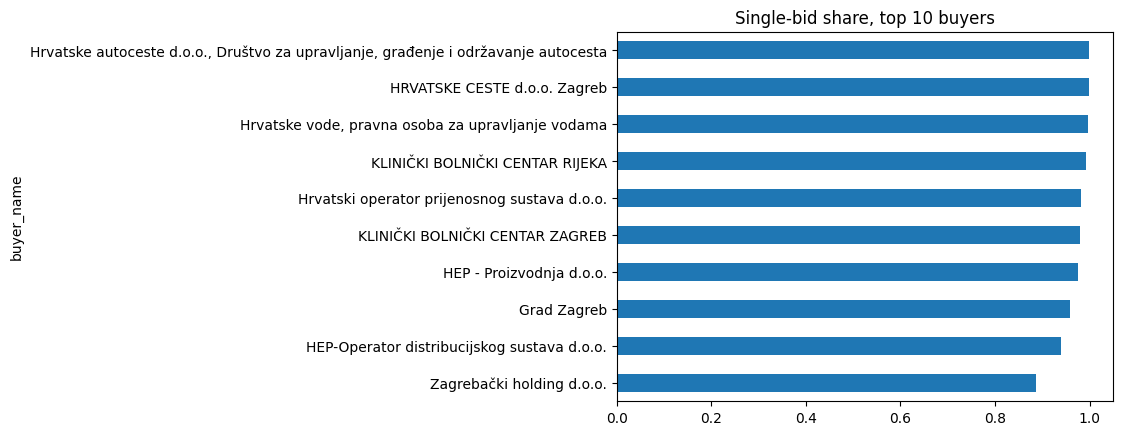

In [93]:
(tenders[tenders['buyer_name'].isin(top_buyers.index)]
    .groupby('buyer_name')['single_bid'].mean()
    .sort_values().plot(kind='barh', title='Single-bid share, top 10 buyers'))
plt.show()

## 11. Correlation (numeric features)

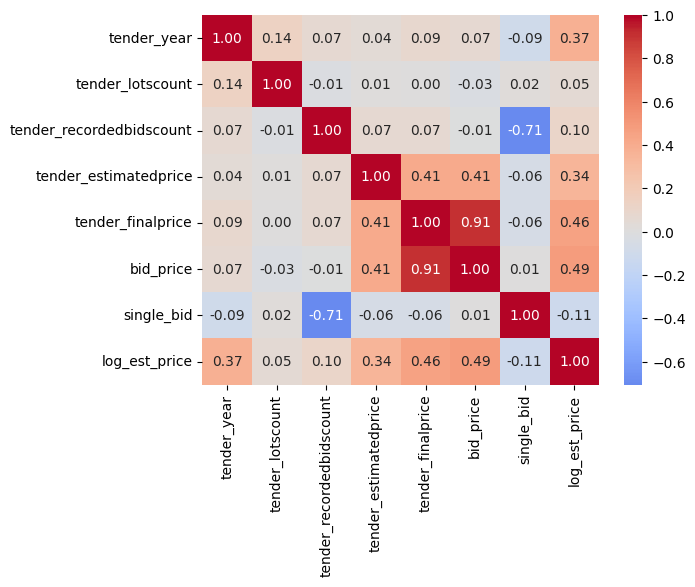

In [94]:
num = tenders.select_dtypes('number').drop(columns=['filter_ok'], errors='ignore')
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

## 12. Save clean tender table for modelling

In [95]:
tenders.to_csv('sample_data/hr_tenders_clean.csv', index=False)
tenders.shape

(167343, 24)

## Takeaways
- Target is skewed, consider `log` or clipping, or a single-bid classifier.
- Supply type, procedure type, CPV sector, buyer type and price look like useful features.
- Next notebook: baseline LinearRegression → RandomForestRegressor, MAE.